In [67]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
import numpy as np
import scanpy as sc
import anndata


OSError: [WinError 127] The specified procedure could not be found. Error loading "c:\Users\Nikla\anaconda3\envs\dynavelo\lib\site-packages\torch\lib\shm.dll" or one of its dependencies.

In [2]:
python_data_dir = r"C:\Users\Nikla\Documents\MoBi_Master_FS.3\Internship AG Höfer\DynaVelo_testing\data"
data = pd.read_csv(rf"{python_data_dir}\cytotrace2_output\velo_df_full.csv", index_col=0, header=0)

In [35]:
data.reset_index(inplace=True)

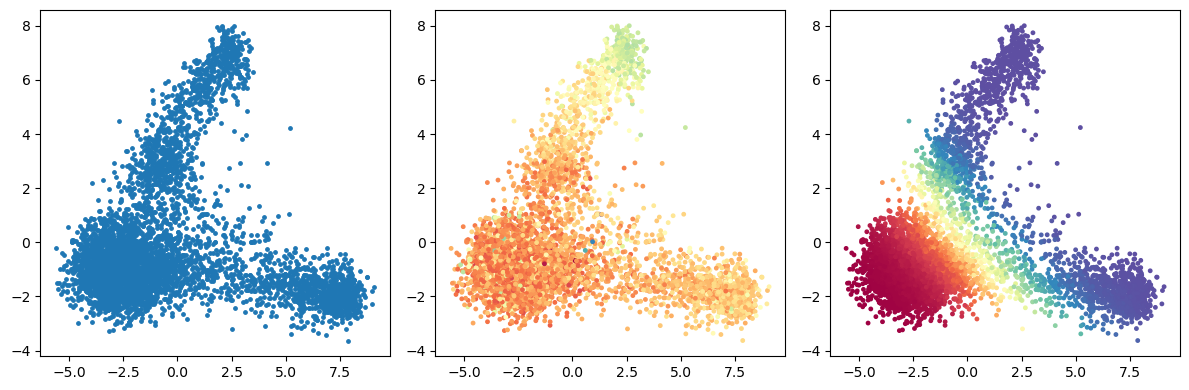

In [36]:
fig, ax = plt.subplots(nrows=1, ncols=3, figsize=(12,4))

ax[0].scatter(data["PC1"], data["PC2"], s=6)
ax[1].scatter(data["PC1"], data["PC2"], c=data["cyto_score"], cmap="Spectral", s=6)
ax[2].scatter(data["PC1"], data["PC2"], c=data["z_diff_proba"], cmap="Spectral", s=6)

plt.tight_layout()
plt.show()

In [37]:
X = np.array([data.loc[:,"PC1"].values, data.loc[:,"PC2"].values]).T
nbrs = NearestNeighbors(n_neighbors=2, algorithm='brute').fit(X)

In [38]:
_, inds = nbrs.kneighbors(X)

In [29]:
X.shape

(2, 5241)

In [45]:
data["z_velo_PC1"] = np.zeros(len(data))
data["z_velo_PC2"] = np.zeros(len(data))

for pair in inds:
    row1 = data.iloc[pair[0]]
    row2 = data.iloc[pair[1]]

    data.loc[pair[0],"z_velo_PC1"] = row2["PC1"]-row1["PC1"]
    data.loc[pair[0],"z_velo_PC2"] = row2["PC2"]-row1["PC2"]

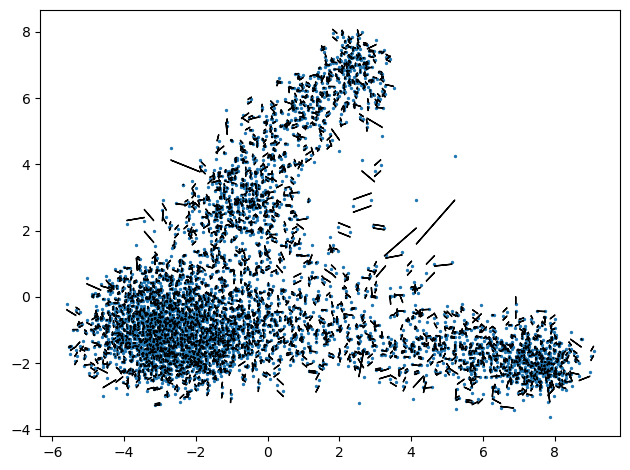

In [42]:
plt.figure()
plt.scatter(data["PC1"], data["PC2"], s=2)

for pair in inds:
    row1 = data.iloc[pair[0]]
    row2 = data.iloc[pair[1]]

    dx=row2["PC1"]-row1["PC1"]
    dy=row2["PC2"]-row1["PC2"]

    plt.arrow(row1["PC1"], row2["PC2"], dx, dy)

plt.tight_layout()
plt.show()

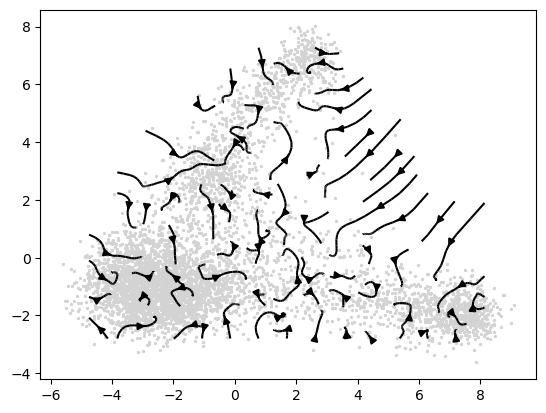

In [49]:
from scipy.interpolate import griddata

xy = data[["PC1", "PC2"]].values
uv = data[["z_velo_PC1", "z_velo_PC2"]].values            # your projected velocities
gx, gy = np.meshgrid(np.linspace(*np.percentile(xy[:,0],[1,99]), 30),
                     np.linspace(*np.percentile(xy[:,1],[1,99]), 30))
U = griddata(xy, uv[:,0], (gx, gy), method="linear")
V = griddata(xy, uv[:,1], (gx, gy), method="linear")
plt.scatter(*xy.T, s=2, c="lightgrey")
plt.streamplot(gx, gy, np.nan_to_num(U), np.nan_to_num(V), density=0.5, color="k")

In [54]:
from scipy.ndimage import gaussian_filter
from scipy.stats import binned_statistic_2d

def orientation_field(xy, v, n=120, sigma=1.0, tensor_sigma=1.0, min_density=0.05):
    x, y = xy[:, 0], xy[:, 1]
    xe = np.linspace(x.min(), x.max(), n + 1)
    ye = np.linspace(y.min(), y.max(), n + 1)

    S = binned_statistic_2d(x, y, v, 'sum', bins=[xe, ye]).statistic
    C = binned_statistic_2d(x, y, None, 'count', bins=[xe, ye]).statistic
    S, C = np.nan_to_num(S).T, np.nan_to_num(C).T          # -> [y, x]

    Sg, Cg = gaussian_filter(S, sigma), gaussian_filter(C, sigma)
    F = Sg / np.maximum(Cg, 1e-9)                          # normalized convolution

    xc, yc = (xe[:-1] + xe[1:]) / 2, (ye[:-1] + ye[1:]) / 2
    gy, gx = np.gradient(F, yc, xc)

    # structure tensor: sign-invariant, then smoothed to suppress noise
    Jxx = gaussian_filter(gx * gx, tensor_sigma)
    Jxy = gaussian_filter(gx * gy, tensor_sigma)
    Jyy = gaussian_filter(gy * gy, tensor_sigma)

    # dominant eigenvector (direction of steepest change)
    theta = 0.5 * np.arctan2(2 * Jxy, Jxx - Jyy)
    U, V = np.cos(theta), np.sin(theta)
    mag = np.sqrt(np.maximum(Jxx + Jyy, 0)) 

    # fix sign ambiguity: align with a global reference direction
    # (principal axis of the points works well for a single trajectory)
    ref = np.linalg.svd(xy - xy.mean(0), full_matrices=False)[2][0]
    flip = (U * ref[0] + V * ref[1]) < 0
    U[flip], V[flip] = -U[flip], -V[flip]

    mask = gaussian_filter(C, sigma) < min_density * gaussian_filter(C, sigma).max()
    return xc, yc, np.ma.array(U, mask=mask), np.ma.array(V, mask=mask), np.ma.array(mag, mask=mask)

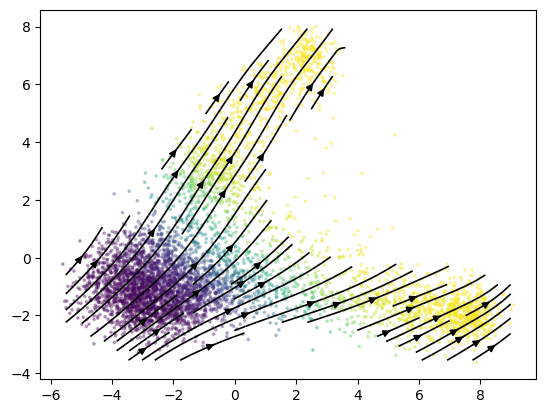

In [66]:
xy = data[["PC1", "PC2"]].values
values = data["z_diff_proba"].values

xc, yc, U, V, mag = orientation_field(xy, values, tensor_sigma=4, sigma=4, n=75, min_density=0.05)
fig, ax = plt.subplots()
ax.scatter(xy[:, 0], xy[:, 1], c=values, s=3, alpha=0.3)
ax.streamplot(xc, yc, U, V, color="black", density=1.2, linewidth=1.2)
#ax.streamplot(xc, yc, U, V, color=mag, density=1.2, linewidth=1.2)#, cmap='viridis')

## Chromatin velocity

In [ ]:
adata_atac = sc.read_h5ad(fr"{python_data_dir}\all_atac_aggregated_peaks.h5ad")